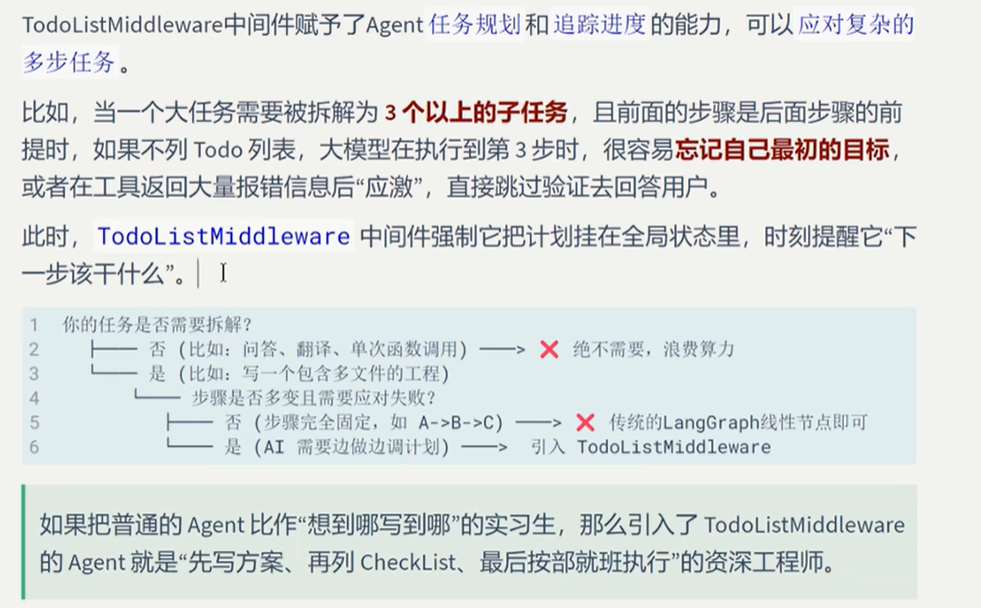

## 定义工具

In [3]:
# 文件操作工具
from pathlib import Path
from langchain_core.tools import tool
import subprocess
import pytest

WORKSPACE= Path("../todo_workspace")

@tool
def list_files(path: str=".") -> str:
    """
    列出工作区指定目录下的文件和子目录.path 只能是相对路径。
    Args:
        path: 工作区的相对路径，一定执行目录，默认为. ,表示工作区根路径，不能访问工作区以外的目录

    """
    target = (WORKSPACE / path).resolve()
    workspaces_root = WORKSPACE.resolve()

    if not str(target).startswith(str(workspaces_root)):
        return "错误，只允许访问工作区内的目录。"
    if not target.exists():
        return f"错误，目录不存在：{path}"

    if not target.is_dir():
        return "错误，不是目录：{path}"

    items = sorted(target.iterdir(),key=lambda p:(p.is_file(),p.name.lower()))

    if not items:
        return f"目录为空：{path}"
    lines = []
    for item in items:
        rel = item.relative_to(workspaces_root)
        kind = "[DIR]" if item.is_dir() else "[FILE]"
        lines.append(f"{kind} {rel.as_posix()}")

    return "\n".join(lines)



@tool
def read_file(path):
    """
    读取工作区中的文本文件的内容。path只能是相对路径

    Args:
        path:  工作区内的文件名

    Returns:

    """
    file_path = (WORKSPACE / path).resolve()
    if not str(file_path).startswith(str(WORKSPACE.resolve())):
        return "错误：只允许读取工作区内的文件。"
    if not file_path.exists():
        return f"错误： 文件不存在{path}"
    return file_path.read_text(encoding="utf-8")

@tool
def write_file(path, content) -> str:
    """
    写入工作区中的文本文件。path只能是相对路径

    Args:
        path:  工作区内的文件名
        content: 写入文件的内容
    """
    file_path = (WORKSPACE / path).resolve()
    if not str(file_path).startswith(str(WORKSPACE.resolve())):
        return  "错误，只允许写入工作区内的文件"
    file_path.write_text(content, encoding="utf-8")

    return f"已写入文件：{path}"

@tool
def run_test() -> str:
    """

    在工作区运行 pytest -q,并返回输出。
    不接受然后参数，返回格式为：
    returncode=0|1
    STDOUT:
    STDERR:
    """
    try:
        result = subprocess.run(
       ["pytest","-q"],
            cwd=str(WORKSPACE),
            capture_output=True,
            text=True,
            timeout=20,
            )
        return (
           f"returncode={result.returncode}\n\n"
           f"STDOUT:\n{result.stdout}\n\n"
           f"STDERR:\n{result.stderr}"

       )
    except Exception as e:
       return f"运行测试失败：{e}"




In [4]:
from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, PIIMiddleware, TodoListMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint



# 1.初始化模型
model = ChatOpenAI(
    # model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

# 2.创建agent对象
agent = create_agent(
    model=model,
    tools=[list_files,read_file,write_file,run_test],
    middleware=[
        TodoListMiddleware(),
    ],
    system_prompt=(
        "你是一个代码修复助手。遇到多步骤任务是，先使用write_todos 制定待办事项: "
        "然后读取文件，修复代码并运行测试。工作全部在工作区下进行。"
    )

)

# 3.调用agent
print("正在执行 Agent 任务。。。")

res = agent.invoke({"messages":[
    HumanMessage(content="请测试并修复工作区下 my_add.py 文件中的代码")
]})

for msg in res["messages"]:
    msg.pretty_print()






正在执行 Agent 任务。。。
================================ Human Message =================================

请测试并修复工作区下 my_add.py 文件中的代码
================================== Ai Message ==================================
Tool Calls:
  list_files (call_v3t46xj9)
 Call ID: call_v3t46xj9
  Args:
    path: .
================================= Tool Message =================================
Name: list_files

错误，目录不存在：.
================================== Ai Message ==================================
Tool Calls:
  list_files (call_ucls55jn)
 Call ID: call_ucls55jn
  Args:
    path: .
================================= Tool Message =================================
Name: list_files

错误，目录不存在：.
================================== Ai Message ==================================
Tool Calls:
  list_files (call_m7yd2r04)
 Call ID: call_m7yd2r04
  Args:
    path: .
================================= Tool Message =================================
Name: list_files

错误，目录不存在：.
================================== Ai Message